# Comptage de mots : Python simple vs pseudo-MapReduce vs Hadoop MapReduce
**Objectif :** On implémente trois méthodes de comptage des occurrences de mots et sur les mêmes fichiers, de tailles croissantes.
On génére les données nous-même en utilisant la répétition et la duplication.

## Environnement
- Windows + Docker Desktop (moteur WSL 2) ; Python et Jupyter côté Windows.
- Hadoop : image officielle `apache/hadoop:3`, cluster pseudo-distribué de 4 conteneurs
  (NameNode, DataNode, ResourceManager, NodeManager), réplication HDFS = 1.
- Données : générées par le notebook (vocabulaire de 20 mots, N = 10 000 lignes, graine fixe).

In [2]:
# On génère les fichiers 

import os
import random

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

VOCABULAIRE = ["chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne",
               "livre", "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture",
               "riviere", "nuage", "foret", "ville", "pomme"]

def generer_base(n, chemin, seed=42):
    """Génère un fichier de n lignes, un mot aléatoire (avec répétition) par ligne."""
    rng = random.Random(seed)              
    mots = rng.choices(VOCABULAIRE, k=n)
    with open(chemin, "w", encoding="utf-8") as f:
        f.write("\n".join(mots) + "\n")
    return chemin

def generer_duplique(chemin_base, m, chemin_sortie):
    """Génère un fichier de m×N lignes en dupliquant m fois les N lignes du fichier de base."""
    with open(chemin_base, "r", encoding="utf-8") as f:
        bloc = f.read()
    with open(chemin_sortie, "w", encoding="utf-8") as f:
        for _ in range(m):
            f.write(bloc)
    return chemin_sortie

N = 10_000
base = generer_base(N, os.path.join(DATA_DIR, "base.txt"))

M_VALUES = [1, 10, 50, 100, 200, 500]
fichiers = {}
for m in M_VALUES:
    chemin = os.path.join(DATA_DIR, f"mots_m{m}.txt")
    generer_duplique(base, m, chemin)
    fichiers[m] = chemin
    taille_mo = os.path.getsize(chemin) / 1e6
    print(f"m={m:>4} -> {m*N:>10,} lignes, {taille_mo:8.2f} Mo  ({chemin})")

m=   1 ->     10,000 lignes,     0.07 Mo  (data\mots_m1.txt)
m=  10 ->    100,000 lignes,     0.73 Mo  (data\mots_m10.txt)
m=  50 ->    500,000 lignes,     3.66 Mo  (data\mots_m50.txt)
m= 100 ->  1,000,000 lignes,     7.32 Mo  (data\mots_m100.txt)
m= 200 ->  2,000,000 lignes,    14.64 Mo  (data\mots_m200.txt)
m= 500 ->  5,000,000 lignes,    36.59 Mo  (data\mots_m500.txt)


## Version 1 : Python simple 
On lit tout le fichier, on le découpe en mots avec split(), et on compte avec un dictionnaire.

In [3]:
def compter_v1(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

res = compter_v1(fichiers[1])
for mot, nb in sorted(res.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"{mot} : {nb}")

jardin : 540
montagne : 535
arbre : 535
chien : 530
oiseau : 526


## Version 2 : pseudo-MapReduce en Python
On reproduit les 3 phases du modèle : map, shuffle, reduce

In [4]:
from collections import defaultdict

def mapper(ligne):
    return [(mot, 1) for mot in ligne.strip().split()]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    return {mot: sum(valeurs) for mot, valeurs in grouped_data.items()}

def compter_v2(fichier):
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    return reducer(shuffle(mapped))

res2 = compter_v2(fichiers[1])
for mot, nb in sorted(res2.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"{mot} : {nb}")

jardin : 540
montagne : 535
arbre : 535
chien : 530
oiseau : 526


## Tests de validité 
On vérifie que V1 et V2 donne les mêmes comptes qu'une référence indépendante, et que le nombre total de mots vaut m x N.

In [5]:
from collections import Counter

def reference(fichier):
    with open(fichier, encoding="utf-8") as f:
        return dict(Counter(f.read().split()))

ref_base = reference(fichiers[1])

for m in [1, 10, 50]:                      
    ref = reference(fichiers[m])
    r1, r2 = compter_v1(fichiers[m]), compter_v2(fichiers[m])
    assert r1 == ref, f"V1 incorrecte pour m={m}"
    assert r2 == ref, f"V2 incorrecte pour m={m}"
    assert sum(r1.values()) == m * N, "nombre total de mots incorrect"
    assert all(r1[mot] == m * ref_base[mot] for mot in ref_base), "duplication incorrecte"
    print(f"m={m:>3} : OK  ({len(r1)} mots distincts, {sum(r1.values()):,} mots au total)")

print("Tous les tests passent.")

m=  1 : OK  (20 mots distincts, 10,000 mots au total)
m= 10 : OK  (20 mots distincts, 100,000 mots au total)
m= 50 : OK  (20 mots distincts, 500,000 mots au total)
Tous les tests passent.


## Version 3 : Hadoop MapReduce
Ici, j'utilise Hadoop dans Docker. Le job utilisé est le wordcount.

In [6]:
# Configuration du cluster 

os.makedirs("hadoop", exist_ok=True)

docker_compose = """services:
  namenode:
    image: apache/hadoop:3
    hostname: namenode
    command: ["hdfs", "namenode"]
    ports: ["9870:9870"]
    env_file: [./config]
    environment:
      ENSURE_NAMENODE_DIR: "/tmp/hadoop-root/dfs/name"
    volumes:
      - ../data:/data
  datanode:
    image: apache/hadoop:3
    command: ["hdfs", "datanode"]
    env_file: [./config]
  resourcemanager:
    image: apache/hadoop:3
    hostname: resourcemanager
    command: ["yarn", "resourcemanager"]
    ports: ["8088:8088"]
    env_file: [./config]
  nodemanager:
    image: apache/hadoop:3
    command: ["yarn", "nodemanager"]
    env_file: [./config]
"""

config = """CORE-SITE.XML_fs.default.name=hdfs://namenode
CORE-SITE.XML_fs.defaultFS=hdfs://namenode
HDFS-SITE.XML_dfs.namenode.rpc-address=namenode:8020
HDFS-SITE.XML_dfs.replication=1
MAPRED-SITE.XML_mapreduce.framework.name=yarn
MAPRED-SITE.XML_yarn.app.mapreduce.am.env=HADOOP_MAPRED_HOME=/opt/hadoop
MAPRED-SITE.XML_mapreduce.map.env=HADOOP_MAPRED_HOME=/opt/hadoop
MAPRED-SITE.XML_mapreduce.reduce.env=HADOOP_MAPRED_HOME=/opt/hadoop
YARN-SITE.XML_yarn.resourcemanager.hostname=resourcemanager
YARN-SITE.XML_yarn.nodemanager.pmem-check-enabled=false
YARN-SITE.XML_yarn.nodemanager.vmem-check-enabled=false
YARN-SITE.XML_yarn.nodemanager.aux-services=mapreduce_shuffle
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.maximum-am-resource-percent=0.5
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.queues=default
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.default.capacity=100
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.default.maximum-capacity=100
"""

with open("hadoop/docker-compose.yaml", "w", newline="\n") as f:
    f.write(docker_compose)
with open("hadoop/config", "w", newline="\n") as f:
    f.write(config)
print("Fichiers écrits :", os.listdir("hadoop"))

Fichiers écrits : ['config', 'docker-compose.yaml']


In [7]:
# Pilotage de Hadoop depuis le notebook

import subprocess
import time

def hadoop_exec(commande):
    """Exécute une commande dans le conteneur NameNode et renvoie sa sortie."""
    r = subprocess.run(
        ["docker", "compose", "exec", "-T", "namenode", "bash", "-c", commande],
        cwd="hadoop", capture_output=True, text=True, encoding="utf-8"
    )
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])
    return r.stdout

JAR = "/opt/hadoop/share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar"
HDFS_IN, HDFS_OUT = "/user/hadoop/input", "/user/hadoop/output"

def charger_dans_hdfs(m):
    """Copie data/mots_m{m}.txt dans HDFS et renvoie la durée de la copie."""
    t0 = time.perf_counter()
    hadoop_exec(f"hdfs dfs -mkdir -p {HDFS_IN} && "
                f"hdfs dfs -put -f /data/mots_m{m}.txt {HDFS_IN}/")
    return time.perf_counter() - t0

def compter_v3(m):
    """Lance le job wordcount Hadoop sur mots_m{m}.txt et renvoie (résultats, durée du job)."""
    sortie = f"{HDFS_OUT}_m{m}"
    hadoop_exec(f"hdfs dfs -rm -r -f {sortie}")           
    t0 = time.perf_counter()
    hadoop_exec(f"hadoop jar {JAR} wordcount {HDFS_IN}/mots_m{m}.txt {sortie}")
    duree = time.perf_counter() - t0
    texte = hadoop_exec(f"hdfs dfs -cat {sortie}/part-r-*")
    resultats = {}
    for ligne in texte.strip().splitlines():
        mot, nb = ligne.split("\t")
        resultats[mot] = int(nb)
    return resultats, duree

In [8]:
# premier job et test 

t_put = charger_dans_hdfs(1)
r3, t_job = compter_v3(1)

print(f"Copie dans HDFS : {t_put:.2f} s   ,   Job wordcount : {t_job:.2f} s")
for mot, nb in sorted(r3.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"{mot} : {nb}")

assert r3 == reference(fichiers[1]), "Hadoop donne des comptes différents."
print("Hadoop donne exactement les mêmes comptes que V1 et V2.")

Copie dans HDFS : 4.52 s   ,   Job wordcount : 18.07 s
jardin : 540
arbre : 535
montagne : 535
chien : 530
oiseau : 526
Hadoop donne exactement les mêmes comptes que V1 et V2.


Les 3 méthodes donnent excatement les mêmes comptes. Le job Hadoop a pris 22,8 s contre quelques millisecondes en Python, ce qui illustre bien la latence de démarrage. 

## Comparaison des performances 
- On utilise les mêmes fichiers pour les 3 méthodes
- On fait 3 exécutiions par fichier
- Pour Hadoop, on faut une exécution par fichier
- On vérifie les comptes

In [9]:
# benchmark 

import statistics
import pandas as pd

def chrono(fonction, fichier, repetitions=3):
    temps = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        res = fonction(fichier)
        temps.append(time.perf_counter() - t0)
    return statistics.median(temps), res

lignes = []
for m in M_VALUES:
    ref = reference(fichiers[m])
    t1, r1 = chrono(compter_v1, fichiers[m])
    t2, r2 = chrono(compter_v2, fichiers[m])
    t_put = charger_dans_hdfs(m)
    r3, t3 = compter_v3(m)
    assert r1 == ref and r2 == ref and r3 == ref, f"résultats différents pour m={m}"
    lignes.append({"m": m, "lignes": m * N,
                   "taille (Mo)": round(os.path.getsize(fichiers[m]) / 1e6, 2),
                   "V1 Python (s)": round(t1, 4),
                   "V2 pseudo-MR (s)": round(t2, 4),
                   "V3 Hadoop job (s)": round(t3, 2),
                   "Copie HDFS (s)": round(t_put, 2)})
    print(f"m={m:>4} terminé  ->  V1 {t1:.3f}s | V2 {t2:.3f}s | Hadoop {t3:.1f}s")

df = pd.DataFrame(lignes)
df.to_csv("resultats_benchmark.csv", index=False)
df

m=   1 terminé  ->  V1 0.005s | V2 0.008s | Hadoop 19.3s
m=  10 terminé  ->  V1 0.033s | V2 0.084s | Hadoop 20.1s
m=  50 terminé  ->  V1 0.192s | V2 0.447s | Hadoop 19.3s
m= 100 terminé  ->  V1 0.368s | V2 0.907s | Hadoop 20.7s
m= 200 terminé  ->  V1 0.774s | V2 1.719s | Hadoop 25.9s
m= 500 terminé  ->  V1 1.658s | V2 4.651s | Hadoop 25.1s


,m,lignes,taille (Mo),V1 Python (s),V2 pseudo-MR (s),V3 Hadoop job (s),Copie HDFS (s)
0,1,10000,0.07,0.0046,0.0084,19.26,3.31
1,10,100000,0.73,0.0335,0.0838,20.14,3.25
2,50,500000,3.66,0.1921,0.4474,19.30,3.44
3,100,1000000,7.32,0.3676,0.9069,20.67,3.69
4,200,2000000,14.64,0.7741,1.7191,25.91,5.59
5,500,5000000,36.59,1.6579,4.6509,25.11,6.24


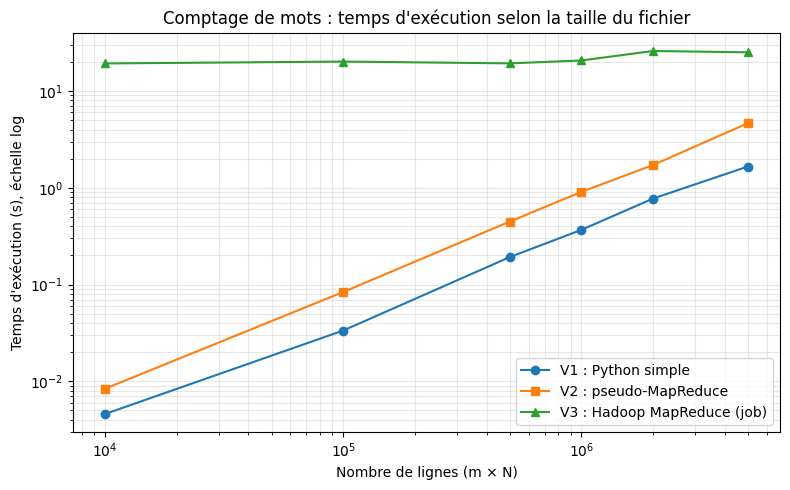

In [10]:
# graphique 

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df["lignes"], df["V1 Python (s)"], "o-", label="V1 : Python simple")
ax.plot(df["lignes"], df["V2 pseudo-MR (s)"], "s-", label="V2 : pseudo-MapReduce")
ax.plot(df["lignes"], df["V3 Hadoop job (s)"], "^-", label="V3 : Hadoop MapReduce (job)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Nombre de lignes (m × N)")
ax.set_ylabel("Temps d'exécution (s), échelle log")
ax.set_title("Comptage de mots : temps d'exécution selon la taille du fichier")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("comparaison_temps.png", dpi=150)
plt.show()

In [11]:
# mémoire de V1 vs V2

import tracemalloc

def pic_memoire(fonction, fichier):
    tracemalloc.start()
    fonction(fichier)
    _, pic = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pic / 1e6

for m in [10, 100]:
    print(f"m={m:>3} : V1 pic = {pic_memoire(compter_v1, fichiers[m]):7.1f} Mo   |   "
          f"V2 pic = {pic_memoire(compter_v2, fichiers[m]):7.1f} Mo")

m= 10 : V1 pic =     6.1 Mo   |   V2 pic =    11.8 Mo
m=100 : V1 pic =    61.1 Mo   |   V2 pic =   119.2 Mo


## Analyse des résultats 

Les 3 méthodes produisent exactement les mêmes comptes sur tous les fichiers.
La V1 (Python simple) est la plus rapide sur toutes les tailles testées.
La V2 (pseudo-MapReduce) est plus lente que V2. La phase map crée une paire (mot, 1) par mot, toutes stockées en mémoire, puis le shuffle les recopie dans des listes. Elle reproduit la structure de MapReduce sans en avoir le bénéfice.
La V3 (Hadoop MapReduce) est plus lent. Il ne gagne pas ici car tous les éléments du cluster tournent sur la même machine, donc il n'y a pas plus de ressources de calcul qu'en Python. De plus, tous nos fichiers
font moins de 128 Mo, qui est la taille d'un bloc HDFS, où chaque job n'a qu'un seul mapper, donc aucun
parallélisme. Hadoop n'est rentable que lorsque les données dépassent la capacité d'une seule machine
(mémoire ou disque) et que le calcul est réparti sur plusieurs nœuds. C

### Exécution réelle sur YARN
Capture de l'interface du ResourceManager (http://localhost:8088) montrant les jobs `word count`
à l'état FINISHED / SUCCEEDED :

![Interface YARN](yarn_capture.png)

## Limites de l'expérience
- Cluster pseudo-distribué sur une seule machine : aucun gain de ressources par rapport à Python.
- Fichiers ≤ 36,6 Mo, donc un seul bloc HDFS et un seul mapper par job.
- Le temps Hadoop inclut un léger surcoût de `docker compose exec` (lancement de la commande dans le conteneur).
- Docker Desktop sous Windows ajoute une couche de virtualisation (VM WSL 2).
- Hadoop mesuré une seule fois par fichier (durée de chaque job) ; V1 et V2 : médiane de 3 exécutions.
- Données synthétiques à vocabulaire réduit (20 mots) : peu de clés distinctes, donc un shuffle léger.

## Conclusion

Nous avons implémenté et testé trois méthodes de comptage de mots, validées par des tests
automatiques : les trois produisent exactement les mêmes résultats sur des fichiers de 10 000 à
5 000 000 de lignes.

| Méthode | Temps (5 M lignes) | Comportement |
|---|---|---|
| V1 : Python simple | ~1,1 s | linéaire, la plus rapide et la plus économe |
| V2 : pseudo-MapReduce | ~3,0 s | linéaire, ~2,7× plus lente et ~2× plus de mémoire que V1 |
| V3 : Hadoop MapReduce | ~22 s (+ ~5 s de copie HDFS) | quasi constant, dominé par ~15 s de latence fixe |

- **V2** montre la structure de MapReduce (map → shuffle → reduce), mais sans parallélisme elle ne
   fait qu'ajouter du coût : matérialiser les paires intermédiaires est cher en temps et en mémoire.
- **Hadoop** paie un coût fixe important (YARN, JVM, HDFS) qui le rend inadapté aux petits et
   moyens volumes. Sur une seule machine, il n'est jamais plus rapide que Python dans nos mesures,
   car son coût par ligne est lui aussi plus élevé.
- Le modèle MapReduce devient pertinent quand **les données dépassent ce qu'une seule machine peut
   traiter** (mémoire, disque) et que le calcul est **réparti sur plusieurs nœuds** proches des
   données. Son intérêt est le passage à l'échelle et la tolérance aux pannes, pas la vitesse
   sur de petits volumes.